**Q3. Portfolio Construction (Risk-Parity Investment)**

**(a) Weights of Assets in 2020-03**

In [13]:
import pandas as pd
import numpy as np

df = pd.read_csv("mystock_L2Risk.csv", parse_dates=['date'])

permno_to_ticker = { #map permnos to ticker
    10107: 'TSLA',
    11308: 'MSFT',
    12490: 'IBM',
    14888: 'BABA',
    86580: 'NVDA',
    93436: 'KO'
}

df['ticker'] = df['PERMNO'].map(permno_to_ticker)
df = df.dropna(subset=['ticker'])
stocks = ['TSLA', 'MSFT', 'IBM', 'BABA', 'NVDA', 'KO']
df = df[df['ticker'].isin(stocks)]
df_pivot = df.pivot(index='date', columns='ticker', values='RET')
df_pivot = df_pivot.sort_index()

df_price = df.pivot(index='date', columns='ticker', values='PRC')
df_shrout = df.pivot(index='date', columns='ticker', values='SHROUT')
df_price = df_price.sort_index()
df_shrout = df_shrout.sort_index()

print("\nData shape:", df_pivot.shape)
print(df_pivot.head())


Data shape: (2516, 6)
ticker          BABA       IBM        KO      MSFT      NVDA      TSLA
date                                                                  
2015-01-02 -0.003271  0.010097 -0.013938 -0.001895  0.003990  0.006674
2015-01-05 -0.025097 -0.015735 -0.042041  0.000000 -0.016890 -0.009303
2015-01-06  0.022970 -0.021566  0.005664  0.007594 -0.030318 -0.014571
2015-01-07 -0.011518 -0.006536 -0.001562  0.012482 -0.002866  0.012705
2015-01-08  0.028395  0.021735 -0.001588  0.012096  0.037889  0.029418


In [25]:
def calculate_risk_parity_weights(returns_df, target_date, stocks):
    target_date = pd.to_datetime(target_date)

    prev_month_end = target_date - pd.offsets.MonthEnd(1)
    prev_month_start = prev_month_end.replace(day=1)

    # get previous month returns using daily data
    mask = (returns_df.index >= prev_month_start) & (returns_df.index <= prev_month_end)
    prev_month_returns = returns_df.loc[mask]

    # daily std dev for each stock
    std_devs = prev_month_returns.std()

    # inverse
    inv_std = 1 / std_devs

    # weights
    weights = inv_std / inv_std.sum()

    return weights, std_devs

# calculate weights for March 2020 using Feb 2020 data
march_2020_weights, march_2020_std = calculate_risk_parity_weights(
    df_pivot, '2020-03-31', stocks
)

print("Risk-Parity Weights for March 2020 (based on Feb 2020 volatility):")
print(f"{'Stock':<10} {'Weight':<12} {'Percentage':<15} {'Feb Std Dev':<15}")
print("-"*55)
for stock in stocks:
    weight = march_2020_weights[stock]
    std = march_2020_std[stock]
    print(f"{stock:<10} {weight:.6f}   {weight*100:>6.2f}%        {std:.6f}")
print("-"*55)
print(f"{'TOTAL':<10} {march_2020_weights.sum():.6f}   {march_2020_weights.sum()*100:>6.2f}%")

Risk-Parity Weights for March 2020 (based on Feb 2020 volatility):
Stock      Weight       Percentage      Feb Std Dev    
-------------------------------------------------------
TSLA       0.157911    15.79%        0.026366
MSFT       0.295297    29.53%        0.014099
IBM        0.195073    19.51%        0.021343
BABA       0.200032    20.00%        0.020814
NVDA       0.101980    10.20%        0.040827
KO         0.049706     4.97%        0.083762
-------------------------------------------------------
TOTAL      1.000000   100.00%


**(b) Plotting Index Performance in 2020 (Risk-Parity, Value-Weighted, Equal-Weighted)**

In [26]:
def calculate_monthly_weights_risk_parity(returns_df, stocks):
    monthly_dates = returns_df.resample('M').last().index
    weights_dict = {}

    for i, date in enumerate(monthly_dates):
        if i == 0:
            weights = pd.Series(1/len(stocks), index=stocks, name=date)
        else:
            prev_month = monthly_dates[i-1]
            prev_month_start = prev_month.replace(day=1)

            mask = (returns_df.index >= prev_month_start) & (returns_df.index <= prev_month)
            prev_returns = returns_df.loc[mask]

            std_devs = prev_returns.std()
            inv_std = 1 / std_devs
            weights = inv_std / inv_std.sum()
            weights.name = date

        weights_dict[date] = weights

    return pd.concat(weights_dict, axis=1).T

def calculate_monthly_weights_equal(returns_df, stocks):
    monthly_dates = returns_df.resample('M').last().index
    weights_dict = {}

    for date in monthly_dates:
        weights = pd.Series(1/len(stocks), index=stocks, name=date)
        weights_dict[date] = weights

    return pd.concat(weights_dict, axis=1).T

def calculate_monthly_weights_value_weighted(returns_df, prices_df, shrout_df, stocks):
    monthly_dates = returns_df.resample('M').last().index
    weights_dict = {}

    for i, date in enumerate(monthly_dates):
        mask = (prices_df.index <= date)

        if mask.any():
            latest_price = prices_df.loc[mask].iloc[-1]
            latest_shrout = shrout_df.loc[mask].iloc[-1]

            market_cap = latest_price * latest_shrout

            weights = market_cap / market_cap.sum()
            weights.name = date
        else:
            weights = pd.Series(1/len(stocks), index=stocks, name=date)

        weights_dict[date] = weights

    return pd.concat(weights_dict, axis=1).T

# monthly returns
monthly_returns = df_pivot.resample('M').apply(lambda x: (1 + x).prod() - 1)

# 2020 only
monthly_returns_2020 = monthly_returns[monthly_returns.index.year == 2020]
rp_weights = calculate_monthly_weights_risk_parity(df_pivot, stocks)
ew_weights = calculate_monthly_weights_equal(df_pivot, stocks)
vw_weights = calculate_monthly_weights_value_weighted(df_pivot, df_price, df_shrout, stocks)

# align
rp_weights_2020 = rp_weights[rp_weights.index.year == 2020]
ew_weights_2020 = ew_weights[ew_weights.index.year == 2020]
vw_weights_2020 = vw_weights[vw_weights.index.year == 2020]

print("\nRisk-Parity Weights for 2020:")
print(rp_weights_2020.round(4))

/tmp/ipykernel_648/847876508.py:57: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_returns = df_pivot.resample('M').apply(lambda x: (1 + x).prod() - 1)
/tmp/ipykernel_648/847876508.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_dates = returns_df.resample('M').last().index



Risk-Parity Weights for 2020:
              TSLA    MSFT     IBM    BABA    NVDA      KO
2020-01-31  0.2270  0.2723  0.2078  0.1225  0.0994  0.0711
2020-02-29  0.2031  0.2718  0.1711  0.1407  0.1409  0.0724
2020-03-31  0.1579  0.2953  0.1951  0.2000  0.1020  0.0497
2020-04-30  0.1429  0.1914  0.1661  0.2709  0.1217  0.1070
2020-05-31  0.1857  0.1781  0.1648  0.2590  0.1215  0.0909
2020-06-30  0.2648  0.1943  0.1819  0.1327  0.1279  0.0984
2020-07-31  0.1972  0.1927  0.1410  0.2133  0.1620  0.0939
2020-08-31  0.1785  0.2491  0.2434  0.1109  0.1588  0.0593
2020-09-30  0.1448  0.2467  0.3058  0.1295  0.1152  0.0580
2020-10-31  0.1574  0.2488  0.2608  0.1757  0.1030  0.0543
2020-11-30  0.1683  0.2689  0.1302  0.1936  0.1286  0.1103
2020-12-31  0.2057  0.2210  0.2377  0.1108  0.1252  0.0997


/tmp/ipykernel_648/847876508.py:25: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_dates = returns_df.resample('M').last().index
/tmp/ipykernel_648/847876508.py:35: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_dates = returns_df.resample('M').last().index


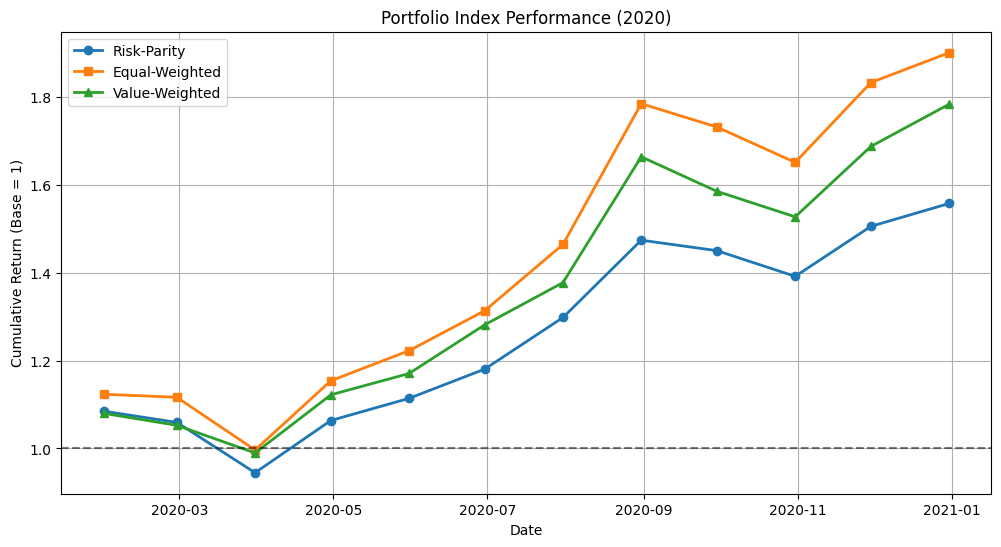

In [30]:
plt.figure(figsize=(12,6))

plt.plot(rp_cumulative.index, rp_cumulative.values,
         label='Risk-Parity', linewidth=2, marker='o')
plt.plot(ew_cumulative.index, ew_cumulative.values,
         label='Equal-Weighted', linewidth=2, marker='s')
plt.plot(vw_cumulative.index, vw_cumulative.values,
         label='Value-Weighted', linewidth=2, marker='^')

plt.title('Portfolio Index Performance (2020)')
plt.xlabel('Date')
plt.ylabel('Cumulative Return (Base = 1)')
plt.legend()
plt.grid(True)

plt.axhline(y=1, color='black', linestyle='--', alpha=0.5)

plt.show()

**(c) Performance Analysis (Equal-Weighted vs. Value-Weighted vs. Risk-Parity)**

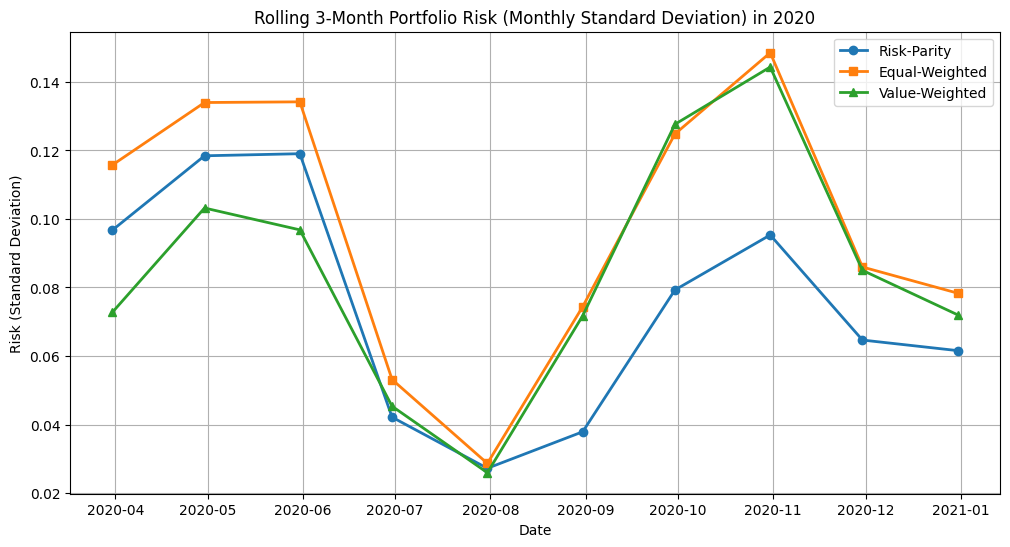

In [32]:
rp_risk = rp_returns.rolling(3).std()
ew_risk = ew_returns.rolling(3).std()
vw_risk = vw_returns.rolling(3).std()

plt.figure(figsize=(12,6))

plt.plot(rp_risk.index, rp_risk.values,
         label='Risk-Parity', linewidth=2, marker='o')
plt.plot(ew_risk.index, ew_risk.values,
         label='Equal-Weighted', linewidth=2, marker='s')
plt.plot(vw_risk.index, vw_risk.values,
         label='Value-Weighted', linewidth=2, marker='^')

plt.title('Rolling 3-Month Portfolio Risk (Monthly Standard Deviation) in 2020')
plt.xlabel('Date')
plt.ylabel('Risk (Standard Deviation)')
plt.legend()
plt.grid(True)

plt.show()

**Comparing Portfolio Performance (Equal-Weighted vs. Value-Weighted vs. Risk-Parity)**

The Equal-Weighted portfolio allocates the same weight (1/6) to every stock, which neglects differences in volatility across stocks. Consequently, stocks with higher volatility contributes more risk to the portfolio, fluctuating portfolio returns.

The Value-Weighted portfolio allocates weights according to market capitalization, therefore allowing larger companies to dominate the portfolio. Although this reflects the market portfolio, it is prone to concentration risk if several large stocks are highly volatile or are performing poorly.

The Risk-Parity portfolio allocates weights based on the inverse of each asset's volatility. When assets with higher volatility receive smaller weights and assets with lower volatility receive larger weights, each asset is ensured to contribute a more balanced share of risk to the portfolio.

This portfolio is considered a better approach than Equal-Weighted and Value-Weighted because it balances risk contributions across assets instead of capital allocation. Risks are better diversified, portfolio volatility is lower, and performance is more stable during market shocks. This is demonstrated by the more stable blue curve on the standard deviation plot for the 3 portfolios above.
